### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom module
from TimeSeriesCustFunc import *

### Loading and Cleaning data

In [5]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [6]:
data.shape

(31972, 14)

In [7]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [8]:
DAFM = data.copy()
DAFM = DAFM[['date', 'price']]
DAFM['date'] = pd.to_datetime(DAFM['date'])
DAFM = DAFM.set_index('date')
DAFM.head()

,price
date,
2008-01-15,400.00
2008-01-15,3636.36
2008-01-15,3636.36
2008-01-15,242.42
2008-01-15,969.70


In [9]:
DAFM = DAFM.resample('MS').mean()
DAFM.head()

,price
date,
2008-01-01,1056.864390
2008-02-01,1136.594375
2008-03-01,1091.044937
2008-04-01,1011.162530
2008-05-01,1011.921319


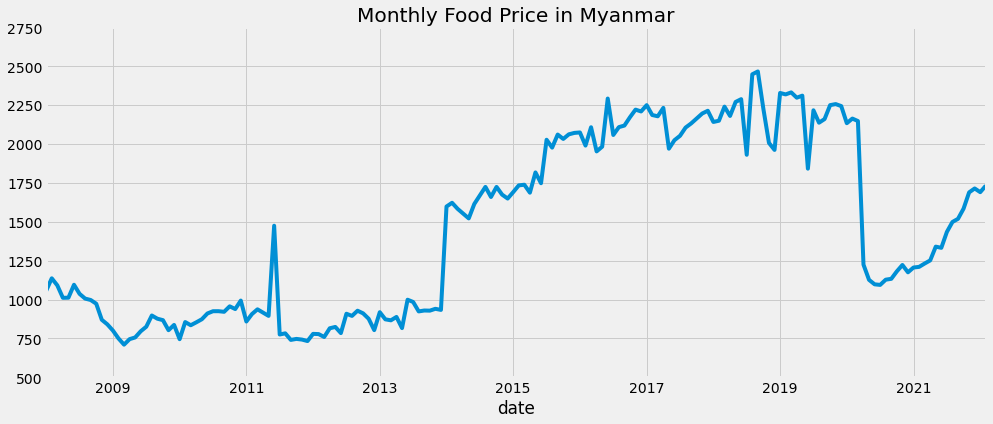

In [17]:
plt.rcParams.update({'figure.figsize': (15,6)})
plt.title("Monthly Food Price in Myanmar")
DAFM['price'].plot()

<BarContainer object of 170 artists>

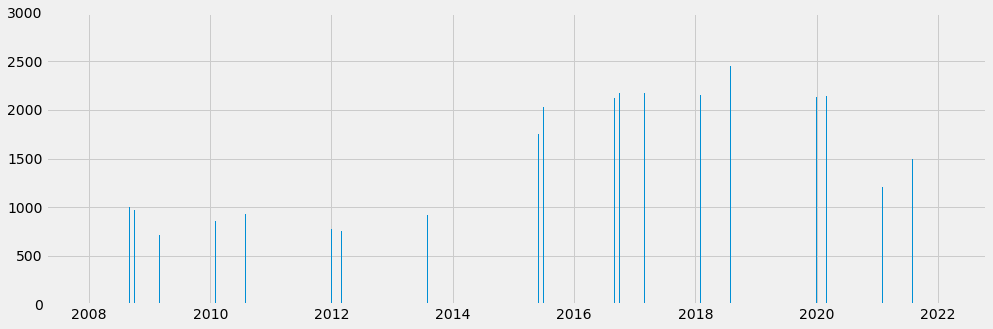

In [15]:
plt.rcParams.update({'figure.figsize': (15,5)})
plt.bar(DAFM.index, DAFM['price'])